# Article 5 — Simulación en Python v0.2

Este cuaderno acompaña un ejercicio académico de pregrado sobre confianza, alcance y recomendaciones. No se utilizan datos reales ni calibración empírica. El modelo está explicado en `docs/Article_5_Especificacion_minima_Python_v0.2.md`.

**Objetivo:** ejecutar una corrida, comprender los indicadores y revisar una trayectoria. Una corrida no permite concluir qué estrategia es superior. El piloto de 25 corridas se realizará después.

En Colab: subir este cuaderno y ejecutarlo desde la primera celda. Si lo solicita, subir también **Article_5_Python_v0.2.zip**, el paquete de código. En Jupyter local: descomprimir primero el ZIP y abrir el cuaderno dentro de su carpeta `notebooks`.


In [1]:
from pathlib import Path
import sys
import zipfile

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / "Article_5_Python_v0.2"]
project = next((p.resolve() for p in candidates if (p / "article5" / "model.py").is_file()), None)
if project is None:
    archive = Path.cwd() / "Article_5_Python_v0.2.zip"
    if not archive.is_file():
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError("Descomprima el ZIP completo y abra el cuaderno desde notebooks/.") from exc
        print("Seleccione Article_5_Python_v0.2.zip")
        files.upload()
    if not archive.is_file():
        raise FileNotFoundError("No se encontró Article_5_Python_v0.2.zip")
    destination = Path.cwd().resolve()
    with zipfile.ZipFile(archive) as z:
        if any(not (destination / name).resolve().is_relative_to(destination) for name in z.namelist()):
            raise ValueError("El ZIP contiene rutas no permitidas")
        z.extractall(destination)
    project = destination / "Article_5_Python_v0.2"
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
from article5 import Config, Model
from article5.io import export_run
from dataclasses import replace
print("Modelo Python disponible. Versión: 0.2")


Modelo Python disponible. Versión: 0.2


## 1. Parámetros y estrategias

La red tiene 600 consumidores en seis comunidades. Se seleccionan 12 promotores iniciales. Cada promotor puede reservar hasta dos intentos por mes y consumir cuatro unidades de energía durante toda su actividad. El envío depende de satisfacción y cooperación; la adopción depende de necesidad, ajuste, confianza, riesgo y exposiciones previas. El compromiso controla la posibilidad de un segundo intento.

| Estrategia | Prioridad |
|---|---|
| A | Relaciones fuertes |
| B | Relaciones débiles, primero las que son puentes |
| C | Rutas A y B con probabilidad 0.50 cada una |
| D | Ruta A con probabilidad 0.80 hasta el mes 12; 0.30 después |
| E | Cualquier contacto elegible, uniformemente |

Se aplican sustituciones cuando el grupo prioritario está vacío. Un vínculo débil no es necesariamente un puente.

Cambie `strategy` para explorar otra estrategia. Conserve `repetition` y los demás parámetros al hacer una comparación emparejada. La semilla Python no reproduce la secuencia NetLogo de la versión anterior.


In [2]:
config = Config.load(project / "config" / "base_v0.2.json")
config = replace(config, strategy="A", repetition=1, experiment_id="notebook_demo_python")
config.validate()
print(f"Estrategia: {config.strategy}; repetición: {config.repetition}")
print(f"Población: {config.population}; comunidades: {config.communities}; períodos: {config.horizon}")
print(f"Riesgo: {config.risk}; mu: {config.mu}; energía por promotor: {config.initial_energy}")


Estrategia: A; repetición: 1
Población: 600; comunidades: 6; períodos: 60
Riesgo: 0.5; mu: 0.2; energía por promotor: 4


## 2. Ejecutar una corrida

El modelo precomputa los sorteos antes de iniciar la difusión. Así las decisiones de una estrategia no desplazan la secuencia disponible para las otras. Los nuevos promotores comienzan a recomendar al mes siguiente de su adopción.


In [3]:
model = Model(config).run()
summary = model.summary()
for label, key in [("Intentos", "attempts"), ("Recomendaciones enviadas", "sent"),
                   ("Nuevas adopciones", "new_adoptions"), ("Adopción total", "total_adoptions"),
                   ("Alcance único", "unique_reach"), ("Exposiciones repetidas", "repeated_exposures"),
                   ("Conversión", "conversion"), ("Cobertura", "coverage"), ("Mes de extinción", "extinction_month")]:
    value = summary[key]
    print(f"{label}: {'NA' if value is None else round(value, 4) if isinstance(value, float) else value}")
assert summary["sent"] == summary["unique_reach"] + summary["repeated_exposures"]
assert summary["total_adoptions"] == len(model.network.seeds) + summary["new_adoptions"]
print("Balances básicos comprobados.")


Intentos: 88
Recomendaciones enviadas: 55
Nuevas adopciones: 15
Adopción total: 27
Alcance único: 43
Exposiciones repetidas: 12
Conversión: 0.2727
Cobertura: 0.0731
Mes de extinción: 7
Balances básicos comprobados.


## 3. Inspeccionar eventos

Cada fila representa un intento, incluido el que no produjo envío. La energía se descuenta al reservarlo. `p_adopt` aparece como `None` cuando no corresponde evaluar adopción; al exportar se escribe `NA`.


In [4]:
for event in model.events[:5]:
    print({key: event[key] for key in ["month", "sender", "receiver", "route", "fallback", "sent", "p_adopt", "adoption"]})


{'month': 1, 'sender': 188, 'receiver': 179, 'route': 'A', 'fallback': False, 'sent': True, 'p_adopt': 0.32650746504051, 'adoption': False}
{'month': 1, 'sender': 115, 'receiver': 104, 'route': 'A', 'fallback': False, 'sent': True, 'p_adopt': 0.40407679599333585, 'adoption': True}
{'month': 1, 'sender': 188, 'receiver': 124, 'route': 'A', 'fallback': False, 'sent': True, 'p_adopt': 0.4607525237040662, 'adoption': True}
{'month': 1, 'sender': 166, 'receiver': 129, 'route': 'A', 'fallback': False, 'sent': True, 'p_adopt': 0.6758503260443435, 'adoption': False}
{'month': 1, 'sender': 32, 'receiver': 23, 'route': 'A', 'fallback': False, 'sent': True, 'p_adopt': 0.3146332271446465, 'adoption': True}


## 4. Trayectoria de la corrida

La adopción total incluye los 12 promotores iniciales; el alcance único los excluye. Las series continúan hasta el mes 60 aunque ya no queden promotores con oportunidades. Esta figura describe una sola realización del modelo.


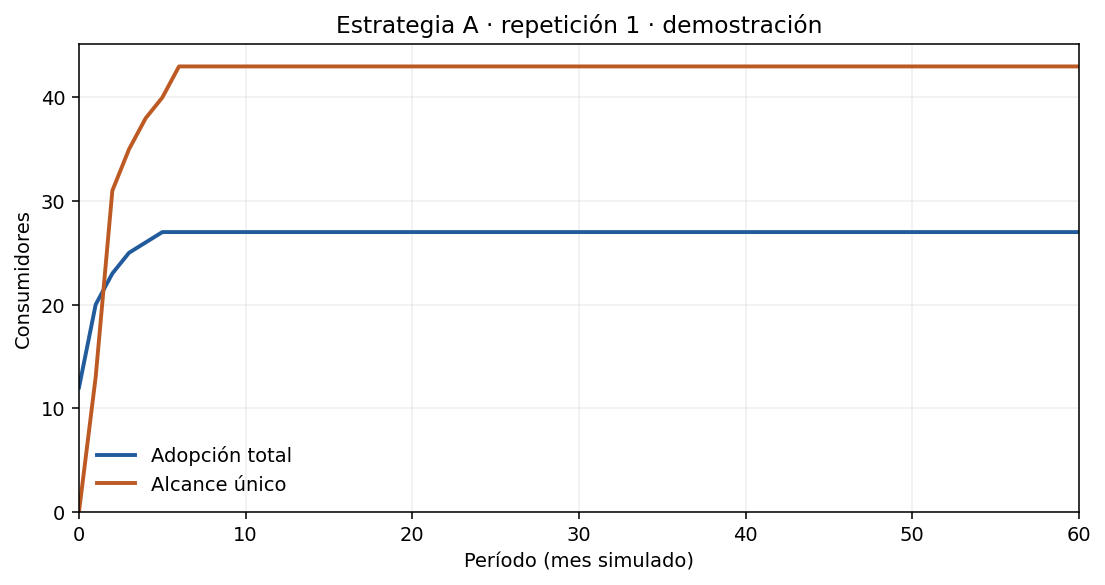

In [5]:
import matplotlib.pyplot as plt

months = [row["month"] for row in model.periods]
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.plot(months, [row["total_adoptions"] for row in model.periods], label="Adopción total", color="#215B9B", linewidth=2)
ax.plot(months, [row["unique_reach"] for row in model.periods], label="Alcance único", color="#BD5A24", linewidth=2)
ax.set(xlabel="Período (mes simulado)", ylabel="Consumidores", title=f"Estrategia {config.strategy} · repetición {config.repetition} · demostración")
ax.set_xlim(0, config.horizon)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## 5. Guardar los datos

La exportación incluye red, eventos, estados, series, cascadas, resumen, diagnósticos, parámetros y un manifiesto con semillas, versión y huellas. Una ejecución con el mismo prefijo reemplaza sus archivos anteriores. Cambie `prefix` si desea conservar ambas.

En Colab estos archivos quedan en el almacenamiento temporal de la sesión. Para conservarlos, descargue la carpeta o cópiela a su Drive desde el panel de archivos; este cuaderno no monta Drive automáticamente.


In [6]:
output_folder = project / "outputs" / "notebook_demo"
prefix = f"demo_{config.strategy}_r{config.repetition}"
manifest = export_run(model, output_folder, prefix, purpose="notebook_demonstration")
print("Archivos guardados en outputs/notebook_demo/.")
print("Manifiesto:", manifest.name)


Archivos guardados en outputs/notebook_demo/.
Manifiesto: demo_A_r1_run_manifest.json


## 6. Repetir todas las pruebas (opcional)

Cambiar `RUN_FULL_VERIFICATION` a `True` ejecuta las 20 pruebas y las siete auditorías. Reemplaza los archivos de verificación anteriores; no ejecuta el piloto. También se puede ejecutar `python run_verification.py` desde una terminal.


In [7]:
RUN_FULL_VERIFICATION = False
if RUN_FULL_VERIFICATION:
    import subprocess
    subprocess.run([sys.executable, str(project / "run_verification.py")], cwd=project, check=True)
else:
    print("Verificación completa desactivada en esta demostración.")


Verificación completa desactivada en esta demostración.


## Preguntas para el estudiante

1. ¿Por qué los intentos pueden superar los envíos, y los envíos superar el alcance único?
2. ¿Qué diferencia hay entre fuerza, confianza, cooperación y compromiso?
3. ¿Qué condiciones permiten que una cascada continúe después de un mes sin envíos?
4. ¿La estrategia D conserva actividad después del mes 12 en esta corrida? ¿Por qué importa antes de interpretar su secuencia?
5. ¿Qué debe conservarse para comparar dos estrategias de forma emparejada?
6. ¿Qué conclusiones requieren repetir la simulación con nuevas semillas?

La siguiente etapa es el piloto de cinco estrategias por cinco repeticiones. No se debe presentar el efecto positivo de confianza impuesto en la ecuación como un descubrimiento empírico ni generalizar el orden observado en una sola corrida.
